# ส่วนที่ 3: การเงินเชิงปริมาณ (Quantitative Finance)
หุ้นที่ใช้: **KBANK, CPALL, OR, AOT**

- 3.1 การจัดเตรียมข้อมูลพื้นฐานและสัดส่วนทางการเงินจาก yFinance
- 3.2 การประเมินมูลค่าที่แท้จริงของสินทรัพย์
- 3.3 การวิเคราะห์ผลตอบแทน (Simple / Log / Expected Return)
- 3.4 การวิเคราะห์/ประเมินความเสี่ยง (Volatility, CV, Sharpe Ratio)
- 3.5 Portfolio Optimization (Covariance & Correlation, Markowitz, Monte Carlo, Efficient Frontier, CML, VaR)

### 0. Setup

In [1]:
# !pip install yfinance pandas numpy matplotlib seaborn scipy mplfinance   # รันครั้งแรกหากยังไม่มีไลบรารี
import warnings                         # ไว้ปิด warning ที่ไม่จำเป็น
warnings.filterwarnings("ignore")       # ปิด warning ไม่ให้รกตอนรัน

import numpy as np                      # คำนวณตัวเลข / array / matrix
import pandas as pd                     # จัดการข้อมูลแบบตาราง
import matplotlib.pyplot as plt         # วาดกราฟพื้นฐาน
import seaborn as sns                   # วาดกราฟเชิงสถิติ
import yfinance as yf                   # ดึงข้อมูลหุ้นจาก Yahoo Finance

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # แสดงทศนิยม 4 ตำแหน่ง
pd.set_option("display.width", 160)                            # ตารางกว้างขึ้น ไม่ตัดคอลัมน์
sns.set_theme(style="whitegrid", palette="deep")               # ธีมกราฟพื้นขาวมีกริด
plt.rcParams["figure.dpi"] = 110                               # กราฟคมขึ้น

TICKERS = ["KBANK", "CPALL", "OR", "AOT"]                      # หุ้นที่กลุ่มเลือก (กลุ่มละ 1 ตัว)
SECTOR_OF = {"KBANK": "Finance & Banking", "CPALL": "Consumer & Retail",
             "OR": "Energy & Utilities", "AOT": "Transportation"}   # หุ้นแต่ละตัวอยู่กลุ่มไหน
SYMBOLS = [f"{t}.BK" for t in TICKERS]                         # หุ้นไทยใน yfinance ต้องเติม .BK
RF = 0.02                                                      # risk-free rate 2% ต่อปี (พันธบัตรรัฐบาลไทย)
TRADING_DAYS = 252                                             # จำนวนวันทำการต่อปี

from scipy.optimize import minimize     # หาน้ำหนักพอร์ตที่เหมาะสม
from scipy.stats import norm            # การแจกแจงปกติ (ใช้กับ VaR)
KE, G = 0.09, 0.03                      # ผลตอบแทนที่ผู้ถือหุ้นต้องการ 9% และอัตราเติบโตระยะยาว 3%

---
## 3.1 การจัดเตรียมข้อมูลพื้นฐานและสัดส่วนทางการเงินจาก yFinance

In [2]:
close = yf.download(SYMBOLS, period="1y", auto_adjust=True, progress=False)["Close"]   # ราคาปิด 1 ปี
close = close.rename(columns=lambda c: c.replace(".BK", ""))[TICKERS].dropna(how="all").ffill().dropna()  # ทำความสะอาด

def get(df, row):                                   # ดึงค่าปีล่าสุดจากงบ ถ้าไม่มีคืน NaN
    try:
        return float(df.loc[row].iloc[0])
    except Exception:
        return np.nan

rows = []
for t in TICKERS:
    tk = yf.Ticker(f"{t}.BK")
    info, fs, bs = tk.info, tk.financials, tk.balance_sheet     # ข้อมูลพื้นฐาน, งบกำไรขาดทุน, งบดุล
    ni, rev = get(fs, "Net Income"), get(fs, "Total Revenue")   # กำไรสุทธิ, รายได้
    eq, assets = get(bs, "Stockholders Equity"), get(bs, "Total Assets")   # ส่วนผู้ถือหุ้น, สินทรัพย์
    rows.append({
        "Ticker": t, "Sector": SECTOR_OF[t],
        "Price": info.get("currentPrice"),          # ราคาปัจจุบัน
        "EPS": info.get("trailingEps"),             # กำไรต่อหุ้น
        "BVPS": info.get("bookValue"),              # มูลค่าทางบัญชีต่อหุ้น
        "DPS": info.get("dividendRate") or 0,       # ปันผลต่อหุ้นต่อปี
        "P/E": info.get("trailingPE"),              # ราคา/กำไร
        "P/BV": info.get("priceToBook"),            # ราคา/มูลค่าทางบัญชี
        "ROE": info.get("returnOnEquity"),          # ROE จาก yfinance
        "Net Margin": ni / rev,                     # อัตรากำไรสุทธิจากงบ
        "ROA": ni / assets,                         # ผลตอบแทนต่อสินทรัพย์จากงบ
        "Equity/Assets": eq / assets,               # สัดส่วนทุนต่อสินทรัพย์ (ยิ่งสูงยิ่งใช้หนี้น้อย)
    })
fund = pd.DataFrame(rows).set_index("Ticker")
fund

,Sector,Price,EPS,BVPS,DPS,P/E,P/BV,ROE,Net Margin,ROA,Equity/Assets
Ticker,,,,,,,,,,,
KBANK,Finance & Banking,247.0000,21.5600,247.7620,12.0000,11.4564,0.9969,0.0851,0.2390,0.0109,0.1275
CPALL,Consumer & Retail,46.2500,3.3600,14.7270,1.6500,13.7649,3.1405,0.1038,0.0285,0.0287,0.1406
OR,Energy & Utilities,12.6000,0.4400,9.1690,0.6000,28.6364,1.3742,0.0477,0.0172,0.0571,0.5747
AOT,Transportation,61.2500,1.3100,9.3910,0.8100,46.7557,6.5222,0.1431,0.2718,0.0863,0.6235


---
## 3.2 การประเมินมูลค่าที่แท้จริงของสินทรัพย์ (Intrinsic Value)
| วิธี | สูตร |
|---|---|
| Graham Number (หุ้นที่ไม่ใช่ธนาคาร) | $\sqrt{22.5 \times EPS \times BVPS}$ |
| Dividend Discount Model (Gordon) | $D_0(1+g)/(K_e - g)$ |
| Justified P/BV (ธนาคาร) | $BVPS \times (ROE - g)/(K_e - g)$ |

Fair Value = ค่าเฉลี่ยของวิธีที่ใช้ได้กับหุ้นตัวนั้น

In [3]:
val = fund[["Price"]].copy()
is_bank = fund["Sector"] == "Finance & Banking"                                              # ธนาคารใช้ P/BV แทน Graham
val["Graham"] = np.sqrt(22.5 * fund["EPS"] * fund["BVPS"]).where((fund["EPS"] > 0) & ~is_bank)   # ใช้ได้เมื่อ EPS > 0
val["DDM"] = (fund["DPS"] * (1 + G) / (KE - G)).where(fund["DPS"] > 0)                       # ใช้ได้เมื่อจ่ายปันผล
val["Justified P/BV"] = (fund["BVPS"] * (fund["ROE"] - G) / (KE - G)).where(is_bank)   # เฉพาะธนาคาร
val["Fair Value"] = val.drop(columns="Price").mean(axis=1)                                   # เฉลี่ยทุกวิธีที่มีค่า
val["Upside"] = val["Fair Value"] / val["Price"] - 1                                         # ราคาต้องขึ้นอีกกี่ % ถึง fair value
val["Status"] = np.where(val["Upside"] > 0, "Undervalued", "Overvalued")
val.round(2)

,Price,Graham,DDM,Justified P/BV,Fair Value,Upside,Status
Ticker,,,,,,,
KBANK,247.0000,NaN,206.0000,227.3600,216.6800,-0.1200,Overvalued
CPALL,46.2500,33.3700,28.3300,NaN,30.8500,-0.3300,Overvalued
OR,12.6000,9.5300,10.3000,NaN,9.9100,-0.2100,Overvalued
AOT,61.2500,16.6400,13.9000,NaN,15.2700,-0.7500,Overvalued


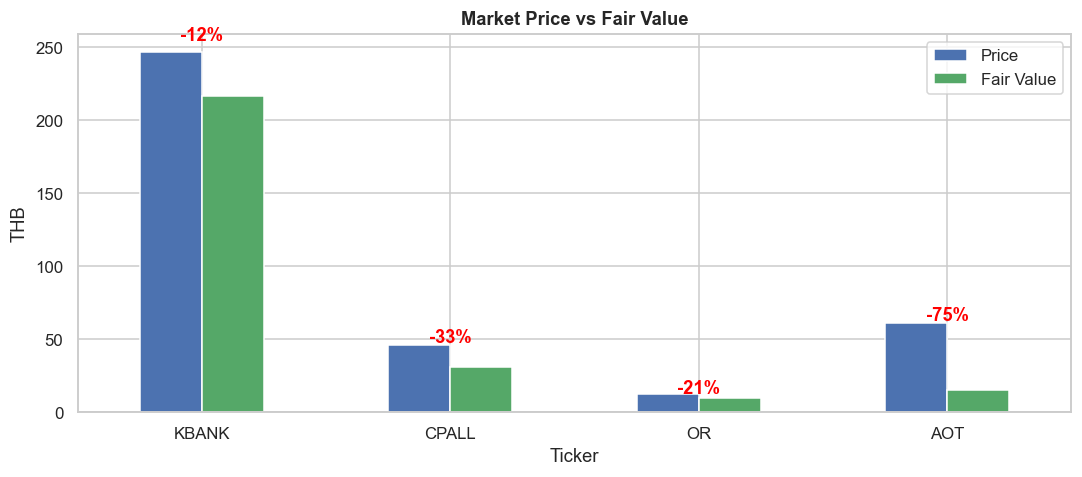

In [4]:
ax = val[["Price", "Fair Value"]].plot.bar(figsize=(10, 4.5), color=["#4C72B0", "#55A868"], rot=0)   # แท่งเทียบราคา vs fair value
for i, (t, r) in enumerate(val.iterrows()):
    ax.text(i, max(r["Price"], r["Fair Value"]) * 1.03, f"{r['Upside']:+.0%}", ha="center",
            color="green" if r["Upside"] > 0 else "red", fontweight="bold")                    # ป้าย % upside
ax.set_title("Market Price vs Fair Value", fontweight="bold"); ax.set_ylabel("THB")
plt.tight_layout(); plt.show()

---
## 3.3 การวิเคราะห์ผลตอบแทน
- **Simple Return** $R_t = P_t/P_{t-1} - 1$ — รวมข้ามสินทรัพย์ได้ (ใช้คิดผลตอบแทนพอร์ต)
- **Log Return** $r_t = \ln(P_t/P_{t-1})$ — รวมข้ามเวลาได้ (ผลตอบแทนหลายวัน = ผลบวกรายวัน)
- **Expected Return** $E[R] = \bar R$ (ค่าเฉลี่ยในอดีต) และแปลงเป็นต่อปีด้วย ×252

In [5]:
simple = close.pct_change().dropna()                         # simple return รายวัน
logr = np.log(close / close.shift(1)).dropna()               # log return รายวัน
ret_tbl = pd.DataFrame({
    "E[R] daily (simple)": simple.mean(),                    # expected return ต่อวัน
    "E[R] daily (log)": logr.mean(),
    "E[R] annual (simple x252)": simple.mean() * TRADING_DAYS,   # ต่อปีแบบ arithmetic
    "E[R] annual (log x252)": logr.mean() * TRADING_DAYS,        # ต่อปีแบบ log (ต่อเนื่อง)
    "Holding-period return": close.iloc[-1] / close.iloc[0] - 1, # ซื้อวันแรกถือถึงวันสุดท้าย
})
ret_tbl["Check: exp(sum log)-1"] = np.exp(logr.sum()) - 1     # ต้องเท่ากับ holding-period return (พิสูจน์คุณสมบัติ log)
ret_tbl

,E[R] daily (simple),E[R] daily (log),E[R] annual (simple x252),E[R] annual (log x252),Holding-period return,Check: exp(sum log)-1
Ticker,,,,,,
KBANK,0.0016,0.0015,0.4035,0.3827,0.4398,0.4398
CPALL,0.0002,0.0001,0.0450,0.0152,0.0146,0.0146
OR,-0.0003,-0.0004,-0.0678,-0.1088,-0.0985,-0.0985
AOT,0.0020,0.0018,0.5084,0.4503,0.5355,0.5355


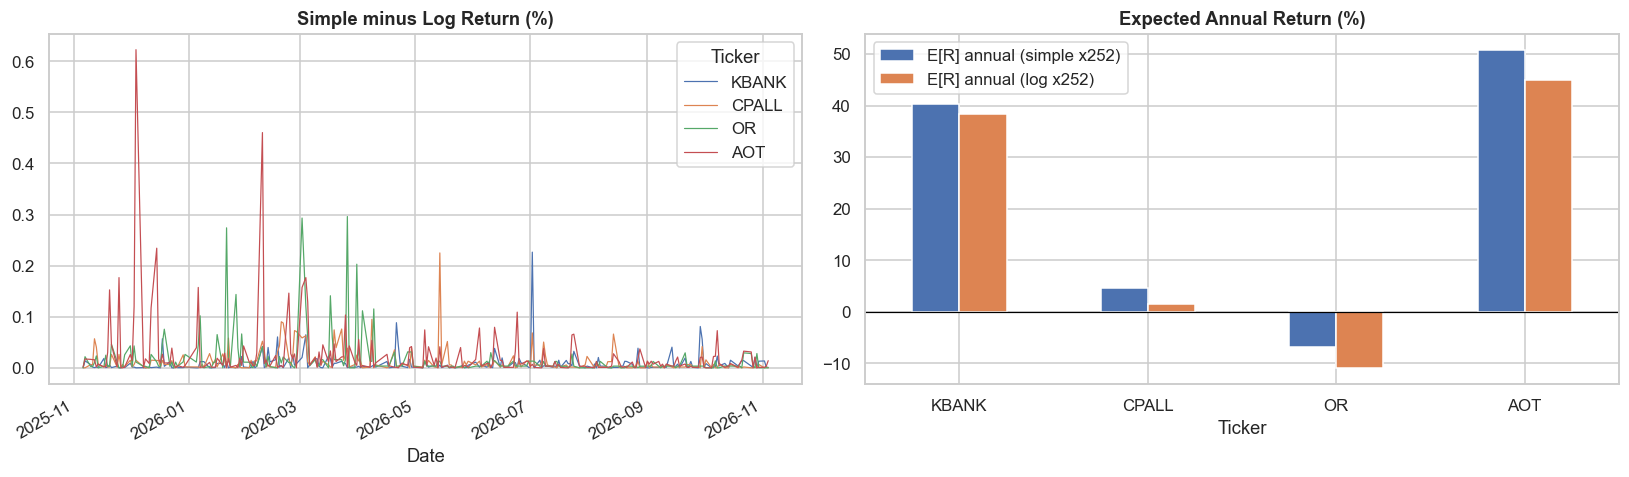

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
(simple - logr).mul(100).plot(ax=axes[0], lw=0.8)            # ส่วนต่าง simple - log (ใหญ่ขึ้นเมื่อวันนั้นขยับแรง)
axes[0].set_title("Simple minus Log Return (%)", fontweight="bold")
ret_tbl[["E[R] annual (simple x252)", "E[R] annual (log x252)"]].mul(100).plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Expected Annual Return (%)", fontweight="bold"); axes[1].axhline(0, color="black", lw=0.8)
plt.tight_layout(); plt.show()

---
## 3.4 การวิเคราะห์/ประเมินความเสี่ยง
- **Volatility** $\sigma_{annual} = \sigma_{daily}\sqrt{252}$
- **Coefficient of Variation** $CV = \sigma/\mu$ (ความเสี่ยงต่อผลตอบแทน 1 หน่วย ยิ่งต่ำยิ่งดี)
- **Sharpe Ratio** $(E[R]-R_f)/\sigma$ (ผลตอบแทนส่วนเกินต่อความเสี่ยง 1 หน่วย ยิ่งสูงยิ่งดี)

In [7]:
risk = pd.DataFrame({
    "Ann. Return": simple.mean() * TRADING_DAYS,                         # ผลตอบแทนต่อปี
    "Ann. Volatility": simple.std() * np.sqrt(TRADING_DAYS),             # ความผันผวนต่อปี
})
risk["CV"] = (risk["Ann. Volatility"] / risk["Ann. Return"]).where(risk["Ann. Return"] > 0)   # CV ใช้ได้เมื่อผลตอบแทน > 0
risk["Sharpe"] = (risk["Ann. Return"] - RF) / risk["Ann. Volatility"]
risk["Rolling 60D Vol (latest)"] = simple.rolling(60).std().iloc[-1] * np.sqrt(TRADING_DAYS)  # ความผันผวน 60 วันล่าสุด
risk.sort_values("Sharpe", ascending=False)

,Ann. Return,Ann. Volatility,CV,Sharpe,Rolling 60D Vol (latest)
Ticker,,,,,
KBANK,0.4035,0.2034,0.5042,1.8850,0.2020
AOT,0.5084,0.3429,0.6745,1.4243,0.2176
CPALL,0.0450,0.2452,5.4440,0.1021,0.1489
OR,-0.0678,0.2876,NaN,-0.3051,0.1492


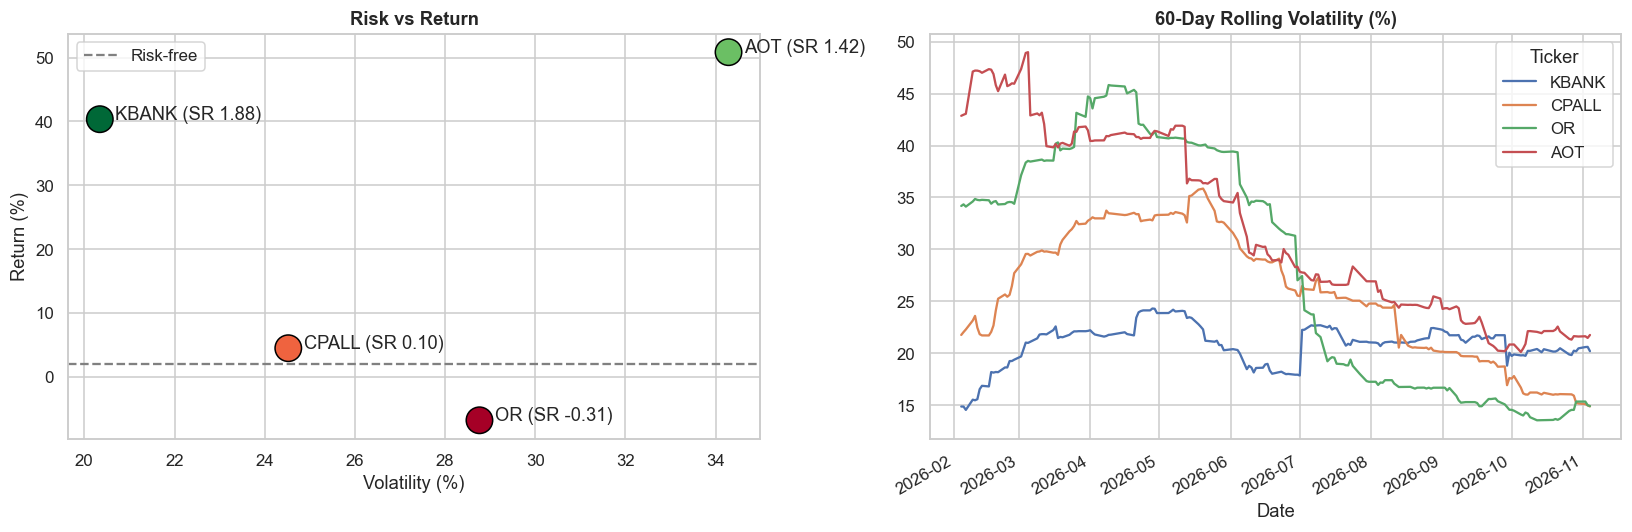

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.scatter(risk["Ann. Volatility"] * 100, risk["Ann. Return"] * 100, s=300, c=risk["Sharpe"], cmap="RdYlGn", edgecolor="black")
for t, r in risk.iterrows():                                              # ใส่ชื่อหุ้นข้างจุด
    ax.annotate(f"{t} (SR {r['Sharpe']:.2f})", (r["Ann. Volatility"] * 100, r["Ann. Return"] * 100), xytext=(10, 0), textcoords="offset points")
ax.axhline(RF * 100, color="grey", ls="--", label="Risk-free"); ax.legend()
ax.set_xlabel("Volatility (%)"); ax.set_ylabel("Return (%)"); ax.set_title("Risk vs Return", fontweight="bold")
(simple.rolling(60).std() * np.sqrt(TRADING_DAYS) * 100).plot(ax=axes[1])   # ความผันผวนเปลี่ยนตามเวลา
axes[1].set_title("60-Day Rolling Volatility (%)", fontweight="bold")
plt.tight_layout(); plt.show()

---
## 3.5 Portfolio Optimization
### 3.5.1 ความสัมพันธ์ระหว่างสินทรัพย์ (Covariance & Correlation)

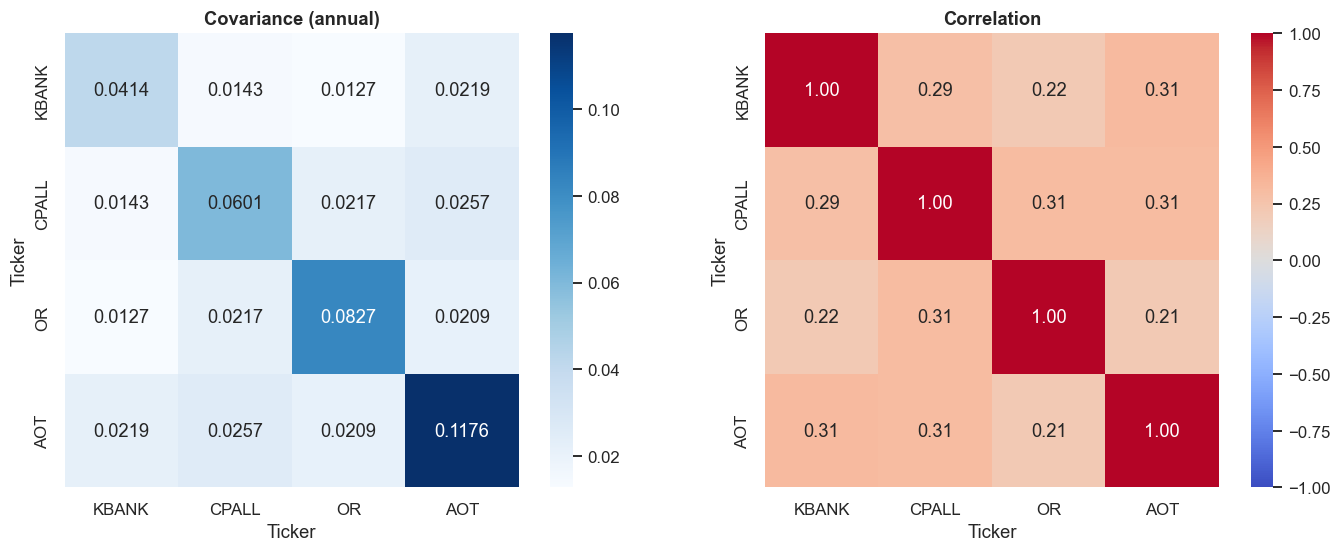

In [9]:
mu = simple.mean() * TRADING_DAYS              # ผลตอบแทนคาดหวังต่อปี (vector)
cov = simple.cov() * TRADING_DAYS              # covariance matrix ต่อปี
corr = simple.corr()                           # correlation matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cov, annot=True, fmt=".4f", cmap="Blues", ax=axes[0], square=True); axes[0].set_title("Covariance (annual)", fontweight="bold")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1], square=True); axes[1].set_title("Correlation", fontweight="bold")
plt.tight_layout(); plt.show()

### 3.5.2 Mean–Variance Optimization (Markowitz Model)
หาน้ำหนัก $w$ ที่ทำให้ Sharpe สูงสุด และที่ทำให้ความเสี่ยงต่ำสุด ภายใต้ $\sum w = 1,\ 0 \le w \le 1$

In [10]:
n = len(TICKERS)
def perf(w):                                         # ผลตอบแทน, ความเสี่ยง, Sharpe ของพอร์ต
    r = w @ mu
    v = np.sqrt(w @ cov @ w)
    return r, v, (r - RF) / v

cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}]   # น้ำหนักรวม 100%
bnds = [(0, 1)] * n                                      # ห้าม short
w0 = np.ones(n) / n                                      # เริ่มจากถือเท่ากัน
w_sharpe = minimize(lambda w: -perf(w)[2], w0, bounds=bnds, constraints=cons).x   # Max Sharpe (minimize ค่าลบ)
w_minvar = minimize(lambda w: perf(w)[1], w0, bounds=bnds, constraints=cons).x    # Min Variance

opt = pd.DataFrame([w_sharpe, w_minvar, w0], columns=TICKERS, index=["Max Sharpe", "Min Variance", "Equal Weight"])
opt[["Return", "Volatility", "Sharpe"]] = np.array([perf(w) for w in [w_sharpe, w_minvar, w0]])   # เติมผลลัพธ์แต่ละพอร์ต
opt.style.format("{:.2%}").format("{:.3f}", subset=["Sharpe"])

,KBANK,CPALL,OR,AOT,Return,Volatility,Sharpe
Max Sharpe,74.44%,0.00%,0.00%,25.56%,43.03%,19.74%,2.079
Min Variance,50.55%,25.82%,18.02%,5.61%,23.19%,16.77%,1.264
Equal Weight,25.00%,25.00%,25.00%,25.00%,22.23%,18.31%,1.105


### 3.5.3 การจำลองพอร์ตและแสดงผลด้วยภาพ: Monte Carlo, Efficient Frontier และ CML

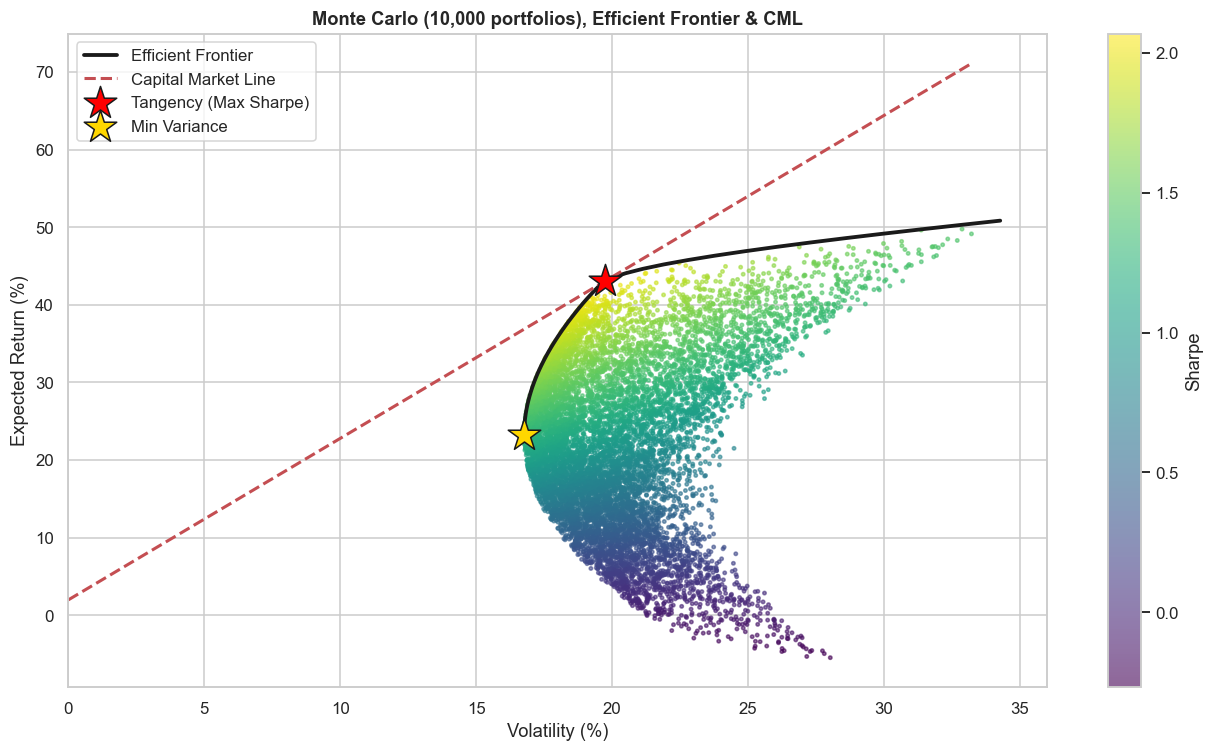

In [11]:
rng = np.random.default_rng(42)
W = rng.dirichlet(np.ones(n), 10_000)                     # สุ่ม 10,000 พอร์ต (น้ำหนักรวม = 1)
mc_r = W @ mu.values                                      # ผลตอบแทนทุกพอร์ต
mc_v = np.sqrt(np.einsum("ij,jk,ik->i", W, cov.values, W))   # ความเสี่ยงทุกพอร์ต
mc_s = (mc_r - RF) / mc_v                                 # Sharpe ทุกพอร์ต

# Efficient frontier: ทุกระดับผลตอบแทนเป้าหมาย หาความเสี่ยงต่ำสุด
ef = []
for target in np.linspace(perf(w_minvar)[0], mu.max(), 50):
    c = cons + [{"type": "eq", "fun": lambda w, t=target: w @ mu - t}]   # เพิ่มเงื่อนไข return = target
    res = minimize(lambda w: perf(w)[1], w0, bounds=bnds, constraints=c)
    if res.success:
        ef.append((res.fun, target))
ef = np.array(ef)

r_t, v_t, s_t = perf(w_sharpe)                            # จุด tangency
fig, ax = plt.subplots(figsize=(12, 7))
sc = ax.scatter(mc_v * 100, mc_r * 100, c=mc_s, cmap="viridis", s=5, alpha=0.6)   # Monte Carlo
fig.colorbar(sc, label="Sharpe")
ax.plot(ef[:, 0] * 100, ef[:, 1] * 100, "k-", lw=2.5, label="Efficient Frontier")
xs = np.linspace(0, mc_v.max(), 50)
ax.plot(xs * 100, (RF + s_t * xs) * 100, "r--", lw=2, label="Capital Market Line")   # CML = Rf + Sharpe_T x σ
ax.scatter(v_t * 100, r_t * 100, marker="*", s=500, c="red", edgecolor="k", zorder=5, label="Tangency (Max Sharpe)")
ax.scatter(perf(w_minvar)[1] * 100, perf(w_minvar)[0] * 100, marker="*", s=500, c="gold", edgecolor="k", zorder=5, label="Min Variance")
ax.set_xlim(left=0); ax.set_xlabel("Volatility (%)"); ax.set_ylabel("Expected Return (%)")
ax.set_title("Monte Carlo (10,000 portfolios), Efficient Frontier & CML", fontweight="bold"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**การตีความ:** จุดทุกจุดที่อยู่ใต้เส้น Efficient Frontier เป็นพอร์ตที่ "ไม่มีประสิทธิภาพ" (มีพอร์ตอื่นที่ความเสี่ยงเท่ากันแต่ได้ผลตอบแทนมากกว่า) ส่วน CML คือเส้นที่ผสมสินทรัพย์ไร้ความเสี่ยงกับพอร์ต Tangency — ทุกจุดบน CML มี Sharpe เท่ากับพอร์ต Tangency ซึ่งสูงที่สุดที่เป็นไปได้

### 3.5.4 มูลค่าของความเสี่ยง (Value at Risk – VaR)
VaR 95% 1 วัน = ผลขาดทุนสูงสุดที่คาดว่าจะไม่เกินด้วยความเชื่อมั่น 95% คำนวณ 3 วิธี + Expected Shortfall (CVaR)

In [12]:
CAPITAL = 1_000_000                                        # เงินลงทุนสมมติ 1 ล้านบาท
p_ret = simple @ w_sharpe                                  # ผลตอบแทนรายวันของพอร์ต Max Sharpe
alpha = 0.05                                               # ระดับนัยสำคัญ (ความเชื่อมั่น 95%)

hist_var = -np.percentile(p_ret, alpha * 100)                              # 1) Historical: percentile ที่ 5 ของข้อมูลจริง
param_var = -(p_ret.mean() + norm.ppf(alpha) * p_ret.std())                # 2) Parametric: สมมติ normal (ppf(0.05) ≈ -1.645)
sim = rng.multivariate_normal(simple.mean(), simple.cov(), 100_000) @ w_sharpe   # 3) Monte Carlo: สุ่มผลตอบแทน 100,000 วัน
mc_var = -np.percentile(sim, alpha * 100)
cvar = -p_ret[p_ret <= -hist_var].mean()                                   # CVaR: ขาดทุนเฉลี่ยในวันที่แย่กว่า VaR

var_tbl = pd.DataFrame({"VaR 95% (1-day)": [hist_var, param_var, mc_var, cvar]},
                       index=["Historical", "Parametric", "Monte Carlo", "CVaR / Expected Shortfall"])
var_tbl["THB (per 1M)"] = var_tbl["VaR 95% (1-day)"] * CAPITAL             # แปลงเป็นจำนวนเงิน
var_tbl["10-day (sqrt-time)"] = var_tbl["VaR 95% (1-day)"] * np.sqrt(10)   # ขยายเป็น 10 วันด้วยกฎ root-time
var_tbl

,VaR 95% (1-day),THB (per 1M),10-day (sqrt-time)
Historical,0.0170,"17,030.4558",0.0539
Parametric,0.0187,"18,742.9268",0.0593
Monte Carlo,0.0187,"18,683.6707",0.0591
CVaR / Expected Shortfall,0.0254,"25,398.8436",0.0803


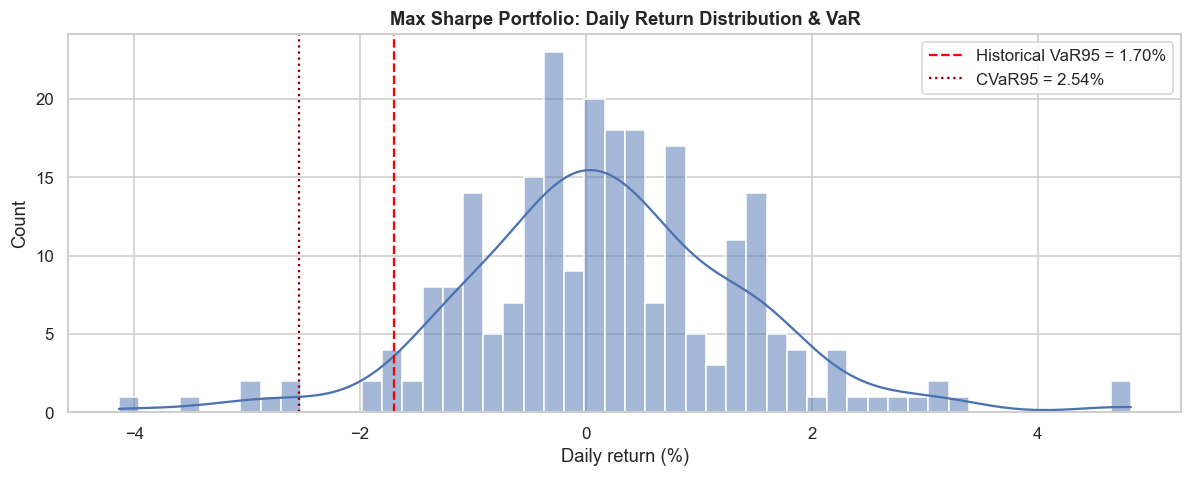

In [13]:
plt.figure(figsize=(11, 4.5))
sns.histplot(p_ret * 100, bins=50, kde=True, color="#4C72B0")              # การกระจายผลตอบแทนพอร์ต
plt.axvline(-hist_var * 100, color="red", ls="--", label=f"Historical VaR95 = {hist_var:.2%}")
plt.axvline(-cvar * 100, color="darkred", ls=":", label=f"CVaR95 = {cvar:.2%}")
plt.title("Max Sharpe Portfolio: Daily Return Distribution & VaR", fontweight="bold")
plt.xlabel("Daily return (%)"); plt.legend(); plt.tight_layout(); plt.show()

### สรุปส่วนที่ 3
- มูลค่าที่แท้จริงจากหลายแบบจำลองช่วยลดอคติของสมมติฐานเดียว แต่หุ้นเติบโตสูง (เช่น AOT) มักถูกประเมินต่ำเมื่อใช้กำไร/ปันผลปัจจุบัน
- Sharpe และ CV ช่วยเทียบหุ้นที่ความเสี่ยงต่างกันได้บนฐานเดียวกัน
- Markowitz + Monte Carlo ให้คำตอบสอดคล้องกัน และ VaR/CVaR แปลความเสี่ยงเป็นจำนวนเงินที่เข้าใจง่าย